# 07 · Compare saved forecasting methods across UKBBS squares

**No retraining or downloads.** Reads **all subfolders** inside `data/predictions/` that contain a `manifest.json` and species CSVs. It does **not** depend on `index.json`.

This notebook produces:

1. **Overall error across all squares** — MAE, RMSE and mean signed error for each method, computed on *identical observed species × square × year rows*.
2. **Per-square error** — a distribution of square-level MAE, and an optional spatial map if `data/processed/locations.csv` exists.
3. **Five representative squares** — choose squares at **0%, 20%, 40%, 60%, and 80%** down the ranking of observed **training-year coverage** for the plotted species. Each plot shows the full **observed training history**, held-out observations, and all models' forecasts.

**Fairness:** error is scored only if *every selected model* has a prediction and a nonmissing actual count. Historical square selection uses training data **only**, never held-out observations to measure coverage. Observed zeros remain distinct from absent surveys. Plotted training history comes from the common processed observation file; individual models may have used different site selection or preprocessing, so check manifests before claiming identical training inputs.

Requires `numpy`, `pandas`, and `matplotlib` (`python -m pip install matplotlib`).

## 1. Discover saved model runs

Run this notebook from the project root or `notebooks/`. This reads your existing prediction outputs without importing or running any model.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "ukbbs" / "forecasting.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Run from the UKBBS project root or its notebooks/ directory")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ukbbs.prediction_comparison import discover_runs, compare_saved_predictions
from ukbbs.coverage_selection import (
    train_cutoff_from_runs,
    load_species_training_history,
    select_squares_by_training_coverage,
)

PREDICTION_ROOT = PROJECT_ROOT / "data" / "predictions"
available_runs = discover_runs(PREDICTION_ROOT)
display(pd.DataFrame([{
    "model": run.label,
    "directory": run.directory,
    "n_species": len(run.species),
    "example_species": ", ".join(run.species[:6]),
} for run in available_runs]))

,model,directory,n_species,example_species
0,grafiti-style (14b9baf1),grafiti-style__14b9baf11c5c,1,CU
1,last_value (fbb562d7),last-value__fbb562d786a4,1,CU
2,one_year_mlp (57e1dcb3),one-year-mlp__57e1dcb352f4,1,CU


## 2. Choose models and species

- `MODEL_FOLDERS = None`: compare **every** run folder found. Or select a list of folder names from the table above.
- `SPECIES_FILTER = None`: pool scores across all species present in **every selected run**. Or use e.g. `["CU"]` for one species.
- `PLOT_SPECIES`: choose a species for the five square plots, or `None` for the first selected species.
- `PLOT_SQUARES = None`: automatically pick squares at **0, 20, 40, 60, and 80% down the training coverage ranking**, using only candidate squares with common observed predictions. Manually specify IDs to override.
- `TRAIN_THROUGH = None`: read the common forecast origin from model manifests. Set it explicitly if your manifests do not record it. Conflicting model cutoffs are rejected, to avoid misleading training/test plots.

Coverage is the number of **distinct years with a recorded species count** at that square in `data/processed/ukbbs_model_data.csv`, through `TRAIN_THROUGH`. A recorded zero counts; absent or missing values do not. This measures *recorded species observations*, **not** general survey effort. The denominator is the number of training years present for this species anywhere in the processed dataset (excluded survey years, such as 2001, remain excluded).

The shared `n_scored` counts still describe the *held-out* observations on which models are compared.

In [2]:
MODEL_FOLDERS = None   # None = every model subfolder; or ["mlp__...", "grafiti__..."]
SPECIES_FILTER = None  # None = all common species; or ["CU", "LK"]
PLOT_SPECIES = None    # None = first common species; or e.g. "CU"
PLOT_SQUARES = None    # None = select by training coverage; or ["...", "..."]
N_PLOT_SQUARES = 5     # 5 picks correspond to rank positions 0%, 20%, 40%, 60%, 80%
TRAIN_THROUGH = None   # None = read from saved run manifests; or explicitly set 2018
SHOW_SPATIAL_MAPS = True

comparison = compare_saved_predictions(
    PREDICTION_ROOT,
    model_folders=MODEL_FOLDERS,
    species=SPECIES_FILTER,
    plot_species=PLOT_SPECIES,
)
print(f"Models compared: {len(comparison.runs)}")
print(f"Species scored: {len(comparison.species)}")
print(f"Species for example squares: {comparison.plot_species}")
print("Model folders:", ", ".join(run.directory for run in comparison.runs))

configs = [json.dumps(run.run_config, sort_keys=True, default=str) for run in comparison.runs]
if len(set(configs)) > 1:
    print("WARNING: run_config differs between selected models. Inspect their manifests "
          "to confirm a comparable evaluation setup.")
    display(pd.DataFrame([{"model": run.label, "run_config": cfg}
                          for run, cfg in zip(comparison.runs, configs)]))

Models compared: 3
Species scored: 1
Species for example squares: CU
Model folders: grafiti-style__14b9baf11c5c, last-value__fbb562d786a4, one-year-mlp__57e1dcb352f4


,model,run_config
0,grafiti-style (14b9baf1),"{""context"": ""observed training years only"", ""d..."
1,last_value (fbb562d7),"{""dataset_file"": ""ukbbs_model_data.csv"", ""test..."
2,one_year_mlp (57e1dcb3),"{""dataset"": ""ukbbs_model_data.csv"", ""evaluatio..."


## 3. Overall error across **all** observed squares

Every model below is scored on the **same observed species–square–year rows**. MAE/RMSE are pooled over those rows (*micro-average*). Species with more surveyed squares and larger counts can dominate the pooled score, so inspect the per-species table too.

**Bias = observed − predicted:** positive values indicate underprediction.

,model,directory,n_species,n_species_squares,n_scored,MAE,RMSE,bias
0,grafiti-style (14b9baf1),grafiti-style__14b9baf11c5c,1,87,316,3.210,5.764,0.593
1,one_year_mlp (57e1dcb3),one-year-mlp__57e1dcb352f4,1,87,316,4.458,7.695,3.402
2,last_value (fbb562d7),last-value__fbb562d786a4,1,87,316,4.984,10.613,-0.661


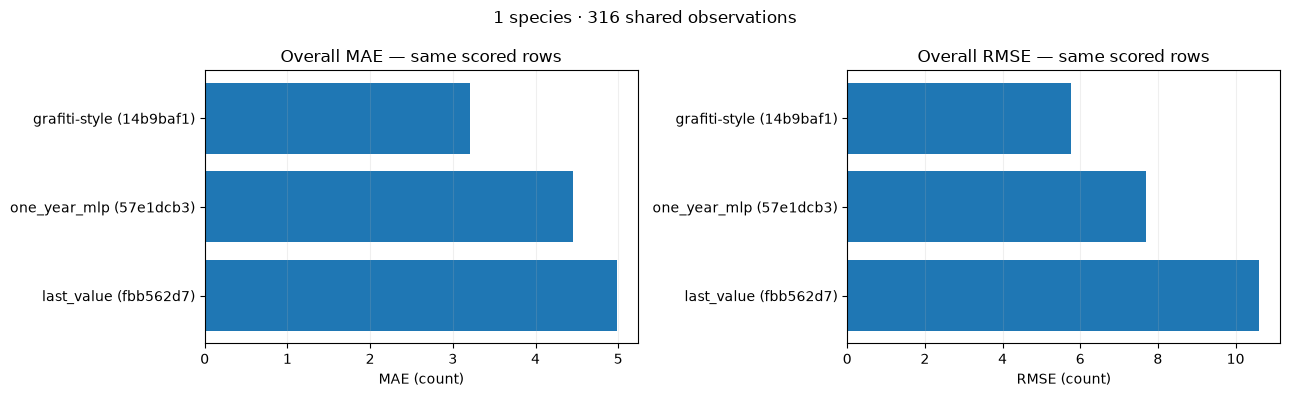

In [3]:
display(comparison.overall.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, max(4, 0.55 * len(comparison.runs) + 2)))
scores = comparison.overall.iloc[::-1]
for ax, metric in zip(axes, ("MAE", "RMSE")):
    ax.barh(scores["model"], scores[metric])
    ax.set(xlabel=f"{metric} (count)", title=f"Overall {metric} — same scored rows")
    ax.grid(axis="x", alpha=0.2)
fig.suptitle(f"{len(comparison.species)} species · {comparison.overall.n_scored.iloc[0]:,} shared observations")
fig.tight_layout()
plt.show()

if len(comparison.species) > 1:
    # Model-by-species MAE shows if an overall win hides losses for other species.
    matrix = comparison.by_species.pivot(index="species", columns="model", values="MAE")
    display(matrix.round(3))

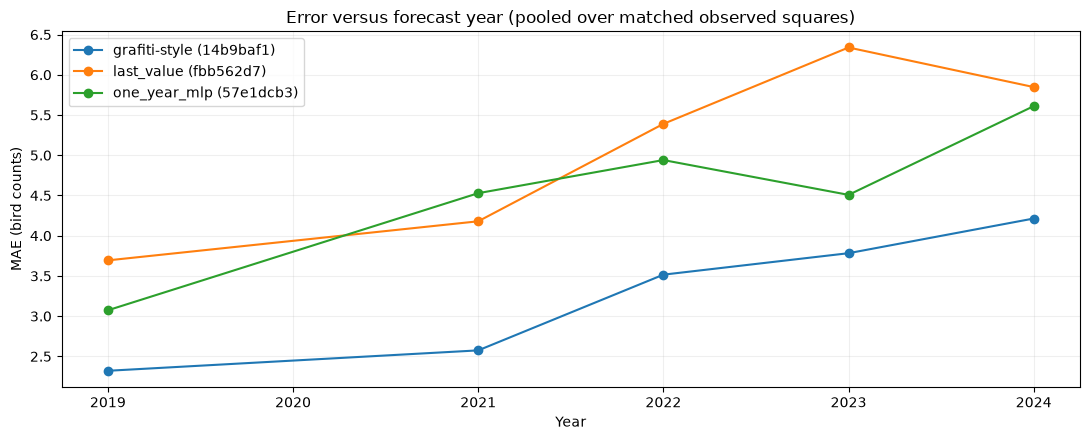

In [4]:
# MAE in each held-out year, pooled across every commonly scored square.
plot_time_col = comparison.runs[0].task["time_col"]
fig, ax = plt.subplots(figsize=(11, 4.5))
for run in comparison.runs:
    g = comparison.by_year.loc[
        comparison.by_year.directory.eq(run.directory)
    ].sort_values(plot_time_col)
    ax.plot(g[plot_time_col], g.MAE, "o-", label=run.label)
ax.set(title="Error versus forecast year (pooled over matched observed squares)",
       xlabel=plot_time_col.title(), ylabel="MAE (bird counts)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


## 4. Error for every square

Each point in the following distribution is one **species × square** (mean absolute error over its shared observed test years). It shows how much performance varies between squares. For multiple species, use `SPECIES_FILTER` to interpret absolute count errors within a single species.

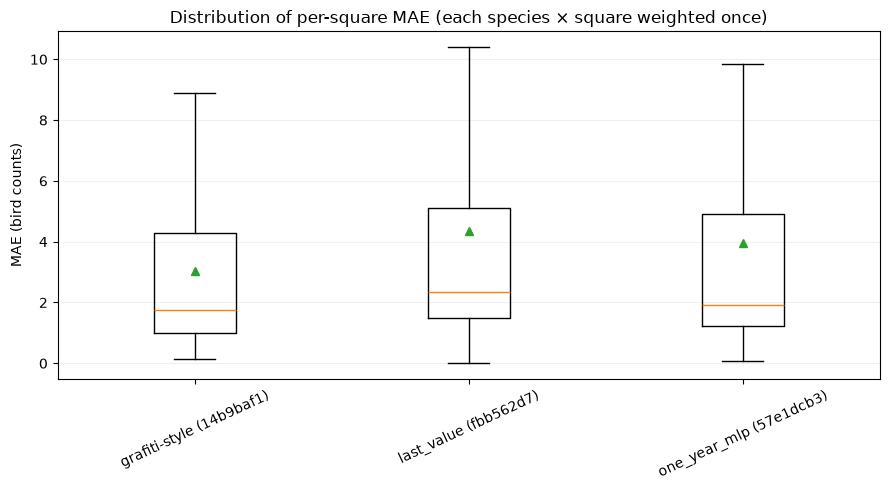

10 largest square-level MAEs for the selected plot species, per model:
grafiti-style (14b9baf1)


,OS_GRID_REF,n_scored,MAE,RMSE,bias
63,SD9592,5,16.27,20.96,-14.36
40,SD5964,3,14.68,16.22,14.68
3,ND4384,5,12.99,19.22,11.15
72,SE1244,5,10.30,10.57,10.30
57,SD9085,5,8.89,13.84,8.89
15,NT2652,3,8.61,8.67,-8.61
73,SE1256,5,7.84,8.88,-4.06
45,SD6819,5,7.77,8.68,7.77
12,NO5381,4,6.65,8.37,6.65
68,SD9842,5,6.51,8.11,6.51


last_value (fbb562d7)


,OS_GRID_REF,n_scored,MAE,RMSE,bias
150,SD9592,5,66.60,68.02,-66.60
160,SE1256,5,17.40,18.98,-17.40
102,NT2652,3,13.67,13.70,-13.67
90,ND4384,5,13.00,19.33,11.40
127,SD5964,3,12.00,13.88,12.00
159,SE1244,5,11.60,11.85,11.60
148,SD9380,4,11.50,13.06,-11.50
132,SD6819,5,11.20,11.82,11.20
123,SD5663,5,10.80,12.36,-10.80
144,SD9085,5,10.40,14.76,10.40


one_year_mlp (57e1dcb3)


,OS_GRID_REF,n_scored,MAE,RMSE,bias
237,SD9592,5,27.36,29.85,27.36
214,SD5964,3,18.88,20.94,18.88
247,SE1256,5,15.83,17.09,12.93
219,SD6819,5,14.48,15.19,14.48
234,SD9284,5,13.70,13.86,13.70
177,ND4384,5,13.61,20.37,12.74
231,SD9085,5,11.74,15.87,11.74
242,SD9842,5,11.58,12.67,11.58
246,SE1244,5,9.83,10.22,9.83
235,SD9380,4,9.71,12.12,9.71


In [5]:
square_errors = comparison.by_square
fig, ax = plt.subplots(figsize=(max(9, len(comparison.runs) * 1.5), 5))
run_order = [run.label for run in comparison.runs]
ax.boxplot(
    [square_errors.loc[square_errors.model.eq(label), "MAE"].to_numpy() for label in run_order],
    showfliers=False, showmeans=True,
)
ax.set_xticks(range(1, len(run_order) + 1))
ax.set_xticklabels(run_order, rotation=25)
ax.set(title="Distribution of per-square MAE (each species × square weighted once)",
       ylabel="MAE (bird counts)")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("10 largest square-level MAEs for the selected plot species, per model:")
for run in comparison.runs:
    frame = square_errors.loc[
        square_errors.directory.eq(run.directory)
        & square_errors.species.eq(comparison.plot_species)
    ].nlargest(10, "MAE")
    print(run.label)
    display(frame[["OS_GRID_REF", "n_scored", "MAE", "RMSE", "bias"]].round(2))

### Optional: show square-level MAE **over space**

Uses saved projected square coordinates (EPSG:3035). If `data/processed/locations.csv` is unavailable, this section skips the maps. Each model uses the **same colour scale** and the same matched square–year rows.

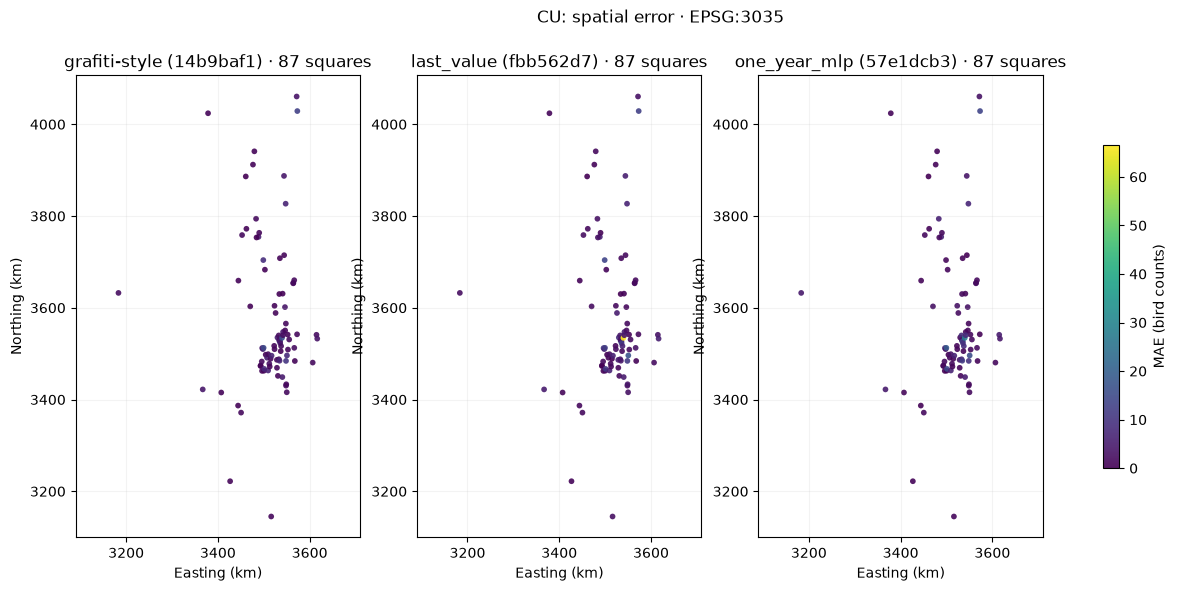

In [6]:
if SHOW_SPATIAL_MAPS:
    paths = [
        PROJECT_ROOT / "data" / "processed" / "locations.csv",
        PROJECT_ROOT / "data" / "processed" / "ukbbs_model_data_with_coordinates.csv",
    ]
    coord_path = next((p for p in paths if p.is_file()), None)
    if coord_path is None:
        print("No coordinate CSV found; skipping maps. Run preprocessing notebook 01 to create locations.csv.")
    else:
        coords = pd.read_csv(coord_path,
            usecols=["OS_GRID_REF", "easting", "northing", "coordinate_crs"],
            dtype={"OS_GRID_REF": "string"})
        if set(coords.coordinate_crs.dropna().unique()) != {"EPSG:3035"}:
            raise ValueError(f"Unexpected coordinate reference system in {coord_path}")
        for col in ("easting", "northing"):
            coords[col] = pd.to_numeric(coords[col], errors="coerce")
        conflicts = coords.groupby("OS_GRID_REF")[["easting", "northing"]].nunique(dropna=False)
        if conflicts.gt(1).any(axis=1).any():
            raise ValueError(f"Conflicting grid-square coordinates in {coord_path}")
        coords = coords.drop_duplicates("OS_GRID_REF")[["OS_GRID_REF", "easting", "northing"]]

        mapped = comparison.by_square.loc[
            comparison.by_square.species.eq(comparison.plot_species)
        ].merge(coords, on="OS_GRID_REF", how="left", validate="many_to_one")
        valid = np.isfinite(mapped[["easting", "northing"]].to_numpy(dtype=float)).all(axis=1)
        if not valid.all():
            print(f"Omitting {(~valid).sum()} model × square rows without coordinates.")
        mapped = mapped.loc[valid]
        if mapped.empty:
            print("No model × square rows have valid coordinates; maps skipped.")
        else:
            cols = min(3, len(comparison.runs))
            rows = int(np.ceil(len(comparison.runs) / cols))
            fig, axes = plt.subplots(rows, cols, figsize=(cols * 5.2, rows * 6), squeeze=False)
            vmax = max(1e-8, float(mapped.MAE.max()))
            for i, run in enumerate(comparison.runs):
                ax = axes.flat[i]
                g = mapped.loc[mapped.directory.eq(run.directory)]
                artist = ax.scatter(g.easting / 1000, g.northing / 1000,
                                    c=g.MAE, cmap="viridis", vmin=0, vmax=vmax,
                                    s=17, alpha=0.9, linewidths=0)
                ax.set(title=f"{run.label} · {g.OS_GRID_REF.nunique():,} squares",
                       xlabel="Easting (km)", ylabel="Northing (km)")
                ax.set_aspect("equal", adjustable="datalim")
                ax.grid(alpha=0.15)
            for j in range(len(comparison.runs), rows * cols):
                axes.flat[j].axis("off")
            fig.colorbar(artist, ax=axes.ravel().tolist(), shrink=0.7, label="MAE (bird counts)")
            fig.suptitle(f"{comparison.plot_species}: spatial error · EPSG:3035", y=0.99)
            plt.show()

## 5. Five squares: **training observations + forecasts on the same axes**

The **shaded left-hand region** shows the real recorded species counts in the training period, through the common forecast origin. The **white right-hand region** shows the test observations and model forecasts. A dotted vertical divider marks the cutoff. Training counts use prominent **blue circles and a solid line**; held-out observations are **open black circles**; model predictions are **dashed lines**. Missing calendar years are gaps, never zeros.

The notebook reports the **number and range of training observations actually loaded** for each square before drawing anything. If it cannot find any historical counts, it raises an error rather than silently drawing prediction-only plots.

Five squares are chosen at 0%, 20%, 40%, 60%, and 80% down the ranked **training-period species observation coverage** distribution among squares predicted by every selected model. You can set `PLOT_SQUARES` to override. These are historical species count records, not necessarily all years a square was surveyed.


TRAINING OBSERVATIONS loaded from: /mnt/bulk/ukbbs-workflow/data/processed/ukbbs_model_data.csv
Species: CU | Training through: 2018
The plots below include both BEFORE and AFTER the forecast cutoff.


,square,coverage_rank,recorded_training_years,first_train_year,last_train_year,test_years_with_actual,forecast_from,forecast_to
0,ND4384,0,24,1994,2018,5,2019,2024
1,NO0700,20,23,1994,2018,2,2019,2021
2,NT0398,40,22,1996,2018,2,2019,2021
3,NJ3940,60,21,1996,2018,5,2019,2024
4,SJ3417,80,21,1994,2018,1,2019,2019


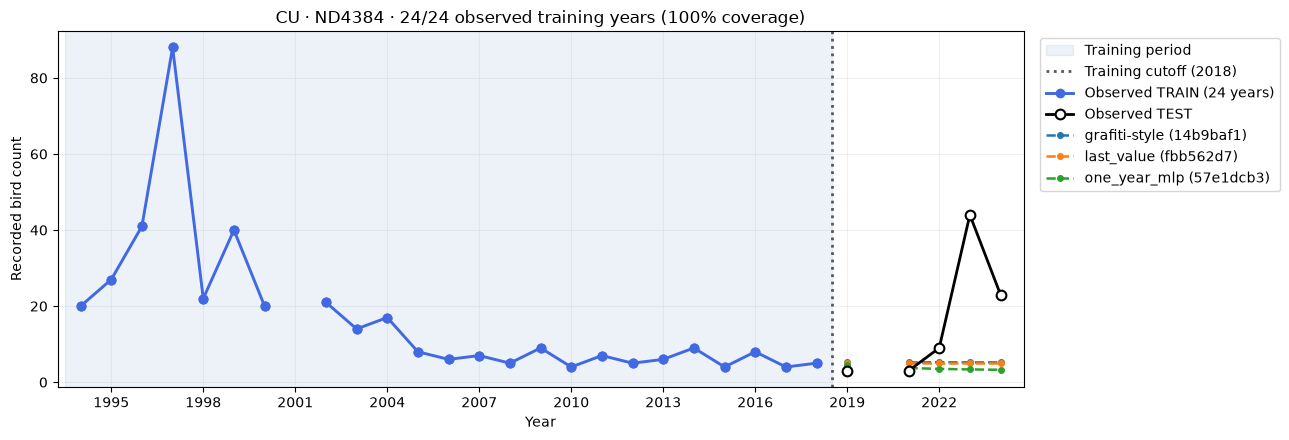

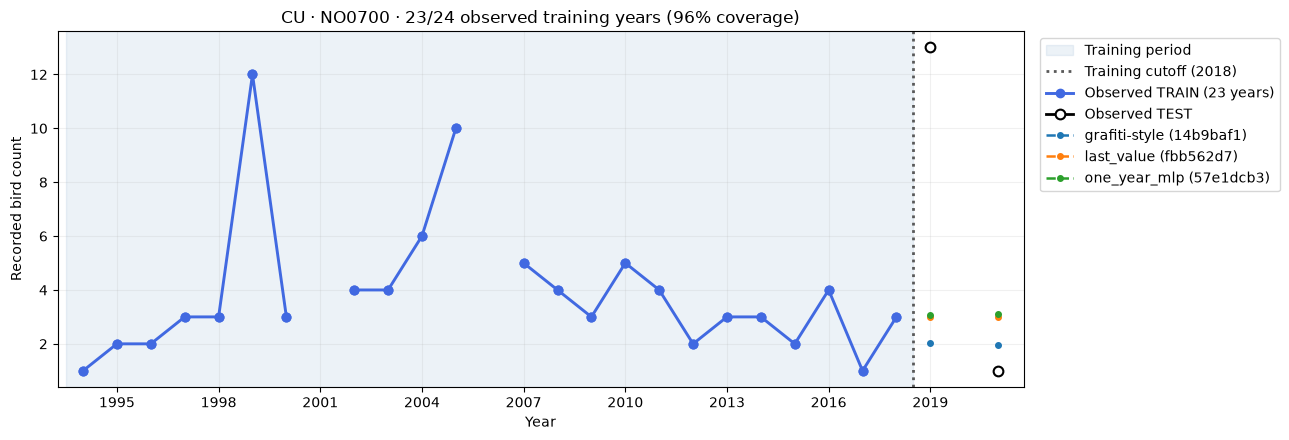

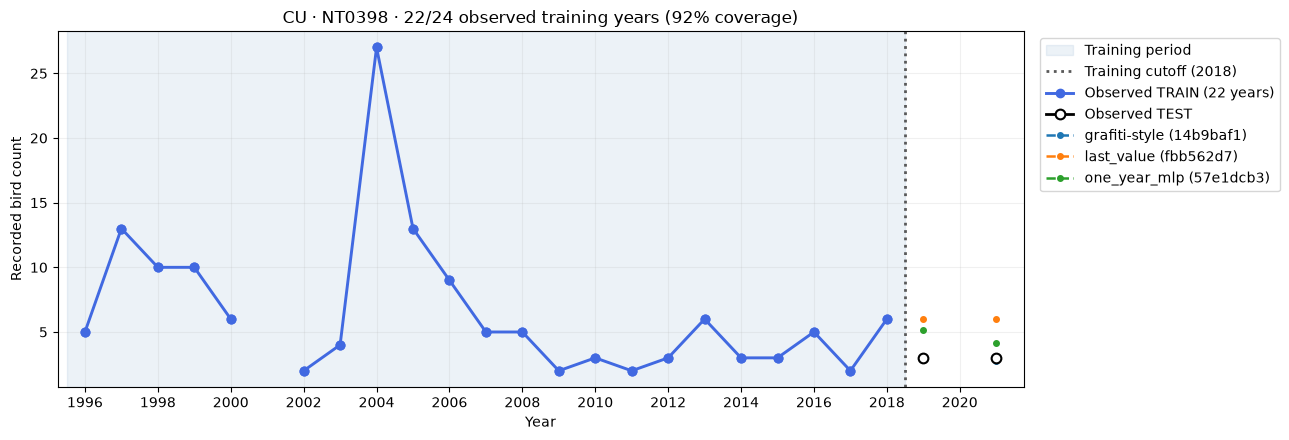

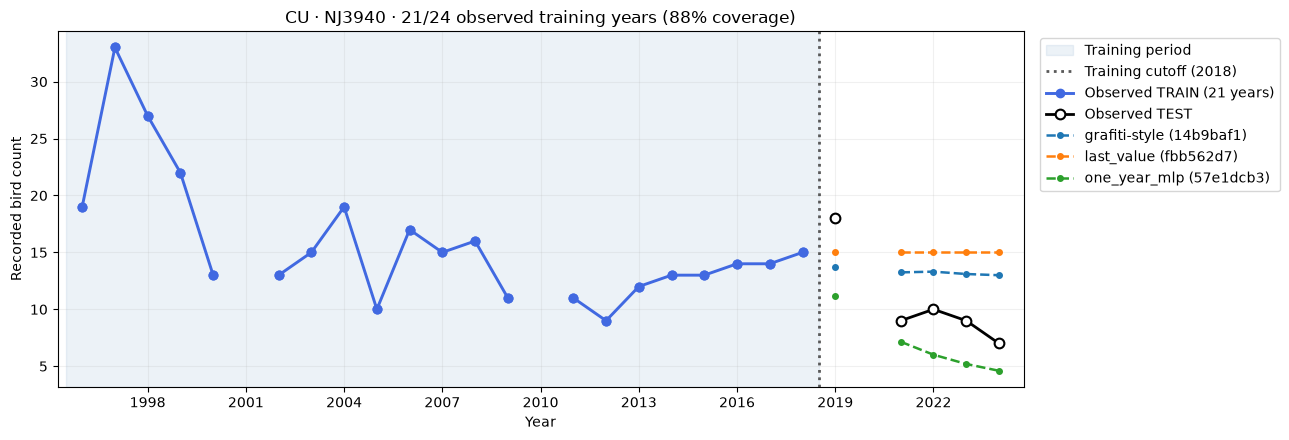

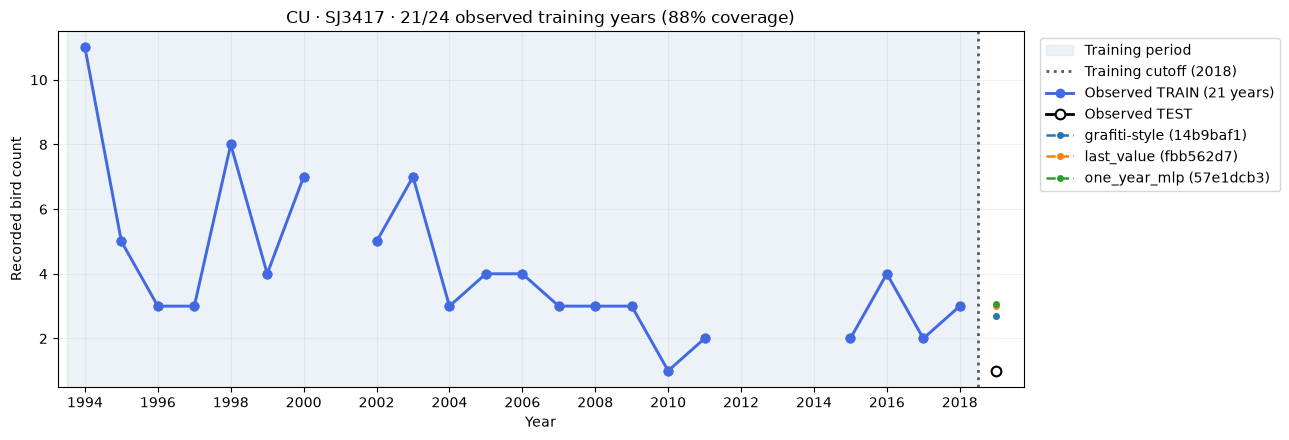

In [7]:
plot_rows = comparison.plot_rows
if plot_rows.empty:
    raise ValueError(f"No common observed predictions for {comparison.plot_species}. "
                     "Choose models with overlapping observed test rows.")

plot_time_col = comparison.runs[0].task["time_col"]
plot_target = comparison.runs[0].task["target"]
if plot_time_col != "year":
    raise ValueError("These UKBBS plots require an annual year key")
cutoff = train_cutoff_from_runs(comparison.runs, override=TRAIN_THROUGH)

# IMPORTANT: the saved prediction files have only test rows. Load the
# *original pre-cutoff observations* separately for plotting the history.
source_options = [
    PROJECT_ROOT / "data" / "processed" / "ukbbs_model_data.csv",
    PROJECT_ROOT / "data" / "processed" / "ukbbs_model_data_with_coordinates.csv",
]
observation_path = next((p for p in source_options if p.is_file()), source_options[0])
history = load_species_training_history(
    observation_path, species=comparison.plot_species,
    train_through=cutoff, target_col=plot_target,
)
selected = select_squares_by_training_coverage(
    history, plot_rows, n=N_PLOT_SQUARES, squares=PLOT_SQUARES,
)

print(f"TRAINING OBSERVATIONS loaded from: {observation_path}")
print(f"Species: {comparison.plot_species} | Training through: {cutoff}")
print("The plots below include both BEFORE and AFTER the forecast cutoff.")

# Build and display an audit table so missing historical points are obvious.
checks = []
for row in selected.itertuples(index=False):
    square = str(row.OS_GRID_REF)
    train_sq = history.loc[history.OS_GRID_REF.astype(str).eq(square)]
    train_sq = train_sq.loc[train_sq.actual.notna()].sort_values("year")
    test_sq = plot_rows.loc[plot_rows.OS_GRID_REF.astype(str).eq(square)]
    if train_sq.empty:
        raise ValueError(f"No observed training counts loaded for {square}. Check {observation_path}")
    if test_sq.empty:
        raise ValueError(f"No matched test predictions for {square}")
    if not (train_sq.year.le(cutoff)).all():
        raise AssertionError("Training data contain post-cutoff observations")
    if not (test_sq[plot_time_col].gt(cutoff)).all():
        raise ValueError("Saved predictions include training years: check model cutoff / manifests")
    checks.append({
        "square": square,
        "coverage_rank": getattr(row, "rank_percentile_from_top", "manual"),
        "recorded_training_years": len(train_sq),
        "first_train_year": int(train_sq.year.min()),
        "last_train_year": int(train_sq.year.max()),
        "test_years_with_actual": int(test_sq.actual.notna().sum()),
        "forecast_from": int(test_sq[plot_time_col].min()),
        "forecast_to": int(test_sq[plot_time_col].max()),
    })
display(pd.DataFrame(checks))

# Keep empty years as NaN, so a gap in surveying is not shown as a zero
# and the line does not falsely connect across missing years.
def annual_with_gaps(years, values):
    table = pd.DataFrame({
        "year": pd.to_numeric(years, errors="raise").to_numpy(dtype=int),
        "value": pd.to_numeric(values, errors="coerce").to_numpy(dtype=float),
    })
    if table.duplicated("year").any():
        raise ValueError("Duplicate years in one square's plot")
    full = np.arange(table.year.min(), table.year.max() + 1)
    return full, table.set_index("year").value.reindex(full).to_numpy()

# One large figure per square, with *all* the history and forecasts on a
# single axis. This is easier to inspect than five compressed small panels.
for row in selected.itertuples(index=False):
    square = str(row.OS_GRID_REF)
    train_sq = (history.loc[history.OS_GRID_REF.astype(str).eq(square)]
                .dropna(subset=["actual"]).sort_values("year"))
    test_sq = (plot_rows.loc[plot_rows.OS_GRID_REF.astype(str).eq(square)]
               .sort_values(plot_time_col))
    fig, ax = plt.subplots(figsize=(13, 4.5))

    first_year = int(train_sq.year.min())
    last_year = int(test_sq[plot_time_col].max())
    ax.axvspan(first_year - 0.5, cutoff + 0.5, color="steelblue", alpha=0.10,
               label="Training period")
    ax.axvline(cutoff + 0.5, color="0.35", linestyle=":", linewidth=2,
               label=f"Training cutoff ({cutoff})")

    # Markers separately guarantee isolated observations remain visible even
    # when all of the surrounding years are unobserved.
    x, y = annual_with_gaps(train_sq.year, train_sq.actual)
    ax.plot(x, y, "o-", color="royalblue", markersize=6, linewidth=2.1,
            zorder=8, label=f"Observed TRAIN ({len(train_sq)} years)")
    ax.scatter(train_sq.year, train_sq.actual, s=40, color="royalblue", zorder=9)

    x_test, y_test = annual_with_gaps(test_sq[plot_time_col], test_sq.actual)
    ax.plot(x_test, y_test, "o-", color="black", markersize=7,
            markerfacecolor="white", markeredgewidth=1.5, linewidth=2,
            zorder=10, label="Observed TEST")
    for i, run in enumerate(comparison.runs):
        xp, yp = annual_with_gaps(test_sq[plot_time_col], test_sq[f"pred_{i}"])
        ax.plot(xp, yp, "o--", linewidth=1.8, markersize=4,
                label=run.label, zorder=3)

    ax.set_xlim(first_year - 0.75, last_year + 0.75)
    ax.set(title=(f"{comparison.plot_species} · {square} · "
                  f"{row.n_training_years}/{row.possible_training_years} observed training years "
                  f"({row.training_coverage_pct:.0f}% coverage)"),
           xlabel="Year", ylabel="Recorded bird count")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=14))
    ax.grid(alpha=0.18)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.tight_layout()
    plt.show()

### Interpreting the plots

- **Blue shaded area and blue circles** are recorded historical bird counts, loaded from the processed observation CSV, *not* from saved prediction files.
- **White region** is the forecast period. Black open markers are held-out observed counts; dashed lines are model predictions.
- The diagnostic table above each set of figures shows which training years were loaded. Check that each square has a nonzero count and that the last observed training year is at or before the cutoff. If you see no blue circles despite nonzero counts in that table, confirm you re-ran **Section 5**, not an old cell or `03_plot_predictions.ipynb`.
- A square may only have a few observed species-years, even if it was surveyed in many years. Missing years are not set to zero or interpolated.
- These plots use the original processed training counts, which may differ from the subset actually used by a particular model (e.g. shorter context windows or site filters).
- Model MAE/RMSE comparisons still use exactly the same matched observed test rows; these visual changes do not affect evaluation.
